<div >
    <img src = "../banner.jpg" />
</div>

<a href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture12/01_NN_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificando digitos con Redes Neuronales 

Uno de los conjuntos de datos ampliamente utilizados para la clasificación de imágenes es el conjunto de datos MNIST (LeCun et al., 1998) de dígitos escritos a mano. En el momento de su lanzamiento en la década de 1990, planteó un desafío formidable para la mayoría de los algoritmos de aprendizaje automático, que constaba de 60.000 imágenes de  resolución 28x28  de píxeles (más un conjunto de datos de prueba de 10,000 imágenes).

 Lograr una alta precisión en el reconocimiento de dígitos fue un componente clave en la automatización de la clasificación de cartas para el servicio postal de EEUU.

Durante más de una década, MNIST sirvió como punto de referencia para comparar algoritmos de aprendizaje automático.

<div >
    <img src = "figs/MNIST_digits.png" />
</div>

## Llamando las librerías

In [1]:
# install.packages("pacman") #Correr esta linea en Google Colab

In [2]:
require('pacman')
p_load("tidyverse","keras3","caret")

Loading required package: pacman



## Cargamos los datos

In [3]:
# set_random_seed() fija los generadores de R, Python y TensorFlow.
# set.seed() solo no alcanza: los pesos iniciales, el orden de los mini-batches
# y las máscaras de dropout los genera TensorFlow.
set_random_seed(20261028)

mnist <- dataset_mnist()

### Muestra de entrenamiento

In [4]:
# X de entrenamiento
x_train <- mnist$train$x
dim(x_train)

[1] 60000    28    28

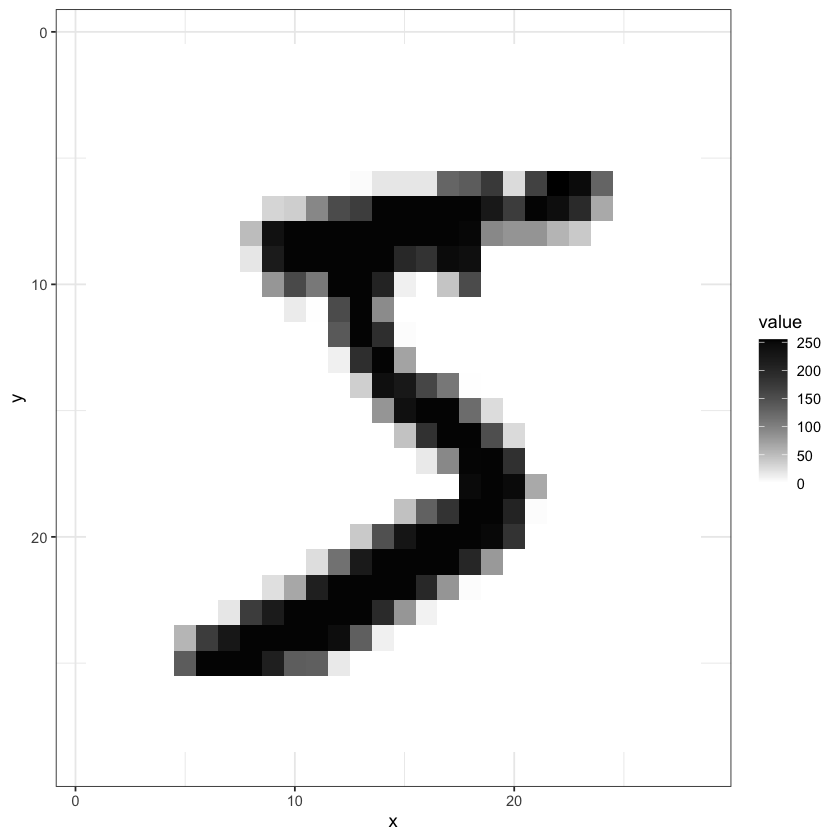

In [5]:
image_1 <- as.data.frame(x_train[1, , ]) 
colnames(image_1) <- seq_len(ncol(image_1))
image_1$y <- seq_len(nrow(image_1))
image_1 <- gather(image_1, "x", "value", -y)
image_1$x <- as.integer(image_1$x)

ggplot(image_1, aes(x = x, y = y, fill = value)) +
  geom_tile() +
  scale_fill_gradient(low = "white", high = "black", na.value = NA) +
  scale_y_reverse() +
  theme_bw()

In [6]:
# Variable dependiente -> target
y_train <- mnist$train$y
head(y_train)

[1] 5 0 4 1 9 2

### Muestra de Prueba

In [7]:
x_test <- mnist$test$x


In [8]:
y_test <- mnist$test$y

### Limpieza de los datos

<div >
    <img src = "figs/Matrices.png" />
</div>

In [9]:
# reshape
x_train <- array_reshape(x_train, c(nrow(x_train), 784))
dim(x_train)

[1] 60000   784

In [10]:
x_test <- array_reshape(x_test, c(nrow(x_test), 784))

In [11]:
# rescale pixeles entre 0 y 1
x_train <- x_train / 255
x_test <- x_test / 255

## Armando la primer red

<div >
    <img src = "figs/red_neuronal.png" />
</div>

Comenzamos creando un nuevo modelo usando `keras_model_sequential()`. Esto define una arquitectura lineal: cada capa que agregamos se apilará en orden, una después de otra. 

In [12]:
set_random_seed(20261028)  # pesos iniciales, mini-batches y dropout reproducibles
model <- keras_model_sequential() 

# Definimos las capas
model %>% 
  layer_dense(units = 10, activation = 'relu', input_shape = c(784)) %>% 
  layer_dense(units = 10, activation = 'softmax')

### Dense

En una capa `layer_dense`, cada neurona está conectada a todas las neuronas de la capa anterior. Los `units`que se especifican en los parámetros, se refieren a la cantidad de neuronas que se deben incluir en una capa determinada de la red neuronal. Es decir, los units son el número de nodos de la capa. Por último, el parámetro `activation`  especifica la función de activación que se va a usar en esa capa de la red.



### Capa de salida: la función softmax

La última capa tiene 10 unidades, una por dígito. Sus valores $z_0,\dots,z_9$ (los *logits*) se convierten en probabilidades con la función softmax, que es el logit multinomial:

$$
p_c = \Pr(y=c \mid x) = \frac{e^{z_c}}{\sum_{l=0}^{9} e^{z_l}}, \qquad c = 0,\dots,9
$$

Las $p_c$ son positivas y suman 1. Solo importan las diferencias entre logits: sumar la misma constante a todos no cambia las probabilidades.

In [13]:
z <- c(1.3, 2.2, 0.7, 1.1, 2.5, 7.3, 3.1, 4.5, 1.3, 1.8)   # logits z_0, ..., z_9

p <- exp(z) / sum(exp(z))

round(p, 4)

[1] 0.0022 0.0055 0.0012 0.0018 0.0075 0.9070 0.0136 0.0552 0.0022 0.0037

#### Target como categóricos


<div >
    <img src = "figs/target.png" />
</div>

In [14]:
y_train <- to_categorical(y_train, 10)
y_test <- to_categorical(y_test, 10)
head(y_train)

0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0
0,0,0,0,1,0,0,0,0,0
0,1,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,1
0,0,1,0,0,0,0,0,0,0


## Modelo Final

In [15]:
summary(model)

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                     │ (None, 10)               │         7,850 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 10)               │           110 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘
 Total params: 7,960 (31.09 KB)
 Trainable params: 7,960 (31.09 KB)
 Non-trainable params: 0 (0.00 B)


## Entrenando la primera red

In [16]:
model %>% compile(
  optimizer = 'adam',
  loss = 'categorical_crossentropy',
  metrics = c('accuracy')
)

### Función de pérdida

La cross-entropy mide el error entre las probabilidades predichas y la clase observada. Con $y_c = 1$ si la imagen es del dígito $c$ y $y_c = 0$ si no (codificación *one-hot*):

$$
L = -\sum_{c=0}^{9} y_c \log p_c = -\log p_{y}
$$

Es menos la log-verosimilitud multinomial. Su gradiente respecto de los logits es simplemente $\partial L / \partial z_c = p_c - y_c$: la probabilidad predicha menos el indicador observado.

Keras usa logaritmo natural. Si la red le asigna probabilidad $0.01$ a la clase correcta, la pérdida es $-\log 0.01 \approx 4.61$:

In [17]:
L <- -y_train[1,]*log(0.01)

L

[1] 0.00000 0.00000 0.00000 0.00000 0.00000 4.60517 0.00000 0.00000 0.00000
[10] 0.00000

In [18]:
sum(L)

[1] 4.60517

### Optimizador

El optimizador es el algoritmo que toma el gradiente calculado por backpropagation y decide *cómo* actualizar los pesos. El descenso de gradiente básico usa una tasa de aprendizaje fija $\epsilon$ para todos los parámetros. `Adam` va más lejos: **adapta la tasa de aprendizaje de cada parámetro por separado**, basándose en el historial de gradientes recientes. En la práctica, esto lo hace más robusto y rápido que el gradiente descendente estándar y es el optimizador por defecto en la mayoría de aplicaciones de deep learning.

[Acá pueden ver una comparación interactiva de optimizadores](https://cede.uniandes.edu.co/Optimizers/NN_%20Optimizadores.html). Para más detalles sobre `Adam` pueden ir [acá](https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/).

### Métrica 

Usamos `accuracy` como métrica de desempeño. 

$$
\text{accuracy} = \frac{\text{correct predictions}}{\text{total predictions}}
$$

Buscamos ver la proporción de dígitos clasificados correctamente

#### Función de pérdida vs. Métrica: ¿cuál es la diferencia?

> La función de pérdida es lo que el algoritmo optimiza; la métrica es lo que tú lees para entender qué tan bien funciona el aprendizaje.

Son dos cosas distintas que cumplen roles distintos:

| | Función de pérdida (`loss`) | Métrica (`metrics`) |
|---|---|---|
| **¿Para qué sirve?** | Guía el entrenamiento (backprop) | Monitorea el desempeño |
| **¿Quién la usa?** | El algoritmo (Adam) | El investigador |
| **¿Debe ser diferenciable?** | **Sí**  necesitamos su gradiente | No necesariamente |
| **Ejemplo** | `categorical_crossentropy` | `accuracy`, F1 |

#### ¿Por qué existe esta distinción? 

En regresión lineal esta distinción **no aparece**: la función de pérdida es el MSE y el MSE también es la métrica que reportas. Optimizas lo mismo que comunicas. 

En clasificación, la situación cambia. Lo que nos importa comunicar es la accuracy (o F1): ¿qué fracción de los dígitos clasifica correctamente? Pero esa pregunta no tiene una respuesta continua y suave; es todo o nada. Y el algoritmo necesita una superficie suave para navegar.

La solución es usar dos objetos distintos con propósitos distintos:
- Una función que el algoritmo pueda optimizar (diferenciable).
- Una métrica que los humanos puedan interpretar (no necesita ser diferenciable).

#### ¿Por qué no optimizamos directamente la accuracy?

Accuracy es una **función escalón**: o acertaste (1) o no (0). Su gradiente es cero casi en todas partes por lo que el optimizador no tendría información para actualizar los pesos.

#### ¿Cómo lo resuelve la cross-entropy?

La **cross-entropy** penaliza de forma continua y diferenciable según qué tan *segura* estaba la red cuando se equivocó:

$$L = -\sum_{c=0}^{9} y_c \log p_c \quad \leftarrow \text{diferenciable, usable en backprop}$$

- Si predijo $p_3 = 0.99$ y era un 3 → pérdida $\approx 0$ (bien y seguro).
- Si predijo $p_3 = 0.51$ y era un 3 → pérdida moderada (bien pero inseguro).
- Si predijo $p_7 = 0.99$ y era un 3 → pérdida enorme (mal y muy seguro).

Esa gradación continua le da información al optimizador en cada paso. Minimizar cross-entropy no garantiza maximizar accuracy, pero en la práctica es un proxy excelente: cuando la red aprende a asignar probabilidades bien calibradas, casi siempre también clasifica correctamente.

Noten además que cross-entropy es exactamente la **log-verosimilitud negativa** del modelo multinomial — tiene una justificación probabilística sólida, no es una elección arbitraria.

#### ¿Puedo monitorear otras métricas?

En  casos, como de desbalance de clases donde la accuracy puede ser  una métrica engañosa; podemos usar el **F1** sin problemas.

## Entrenamiento

Estamos listos para entrenar la red. La semilla ya quedó fijada con `set_random_seed()` al cargar los datos y antes de construir cada red, así que los pesos iniciales, el orden de los mini-batches y las máscaras de dropout son reproducibles.

Con `validation_split = 0.2`, Keras reserva para validación el **último** 20% de las observaciones de entrenamiento 

In [19]:
history <- model %>% fit(
  x_train, y_train,        
  epochs = 30,             # Número de veces que el modelo ve todo el dataset
  batch_size = 512,        # Tamaño del mini-batch (2^9): controla cuántos datos se usan para calcular el gradiente
  validation_split = 0.2   # Reserva el 20% de los datos de entrenamiento para validación
)

Durante el entrenamiento, el modelo sigue estos pasos:

* Recibe los datos de entrenamiento (`x_train`, `y_train`).
* Aprende a asociar entradas y salidas (por ejemplo, imágenes con etiquetas).
* Evalúa su desempeño en un conjunto de validación reservado automáticamente.

Al llamar la función `fit()`, el modelo se ajusta a los datos. En este ejemplo especificamos dos hiperparámetros clave: `epochs` y `batch_size`

- Un `epoch` es una pasada **completa** del conjunto de entrenamiento a través de la red. Es decir, todos los datos se procesan una vez, tanto hacia adelante (forward pass, donde calculamos las predicciones) como hacia atrás (backpropagation). Dentro de cada epoch, los pesos se actualizan $\lceil N_{train} / \text{batch\_size} \rceil$ veces, una por cada mini-batch: con $N_{train} = 48.000$ y lotes de 512 son 94 actualizaciones por época (el último lote es más chico). El número de épocas define cuántas veces se repite este proceso.


- El `batch size` determina cuántas muestras se procesan antes de actualizar los pesos del modelo. En lugar de calcular el gradiente con todo el dataset (batch gradient descent) o con una sola observación (stochastic gradient descent), usamos mini-batches. En este ejemplo, se usan bloques de 512 observaciones. Recordemos
    - `batch_size = 1`: es **Stochastic Gradient Descent (SGD)** → más ruido.
    - `batch_size = nrow(X)` (todo el dataset): es **Batch Gradient Descent** → estable pero lento.
    - `batch_size =2^k` (valores típicos: 32, 64, 128, 256, 512): es **Mini-batch Gradient Descent**, combina velocidad y estabilidad. (GPUs trabajan mejor con potencias de 2)


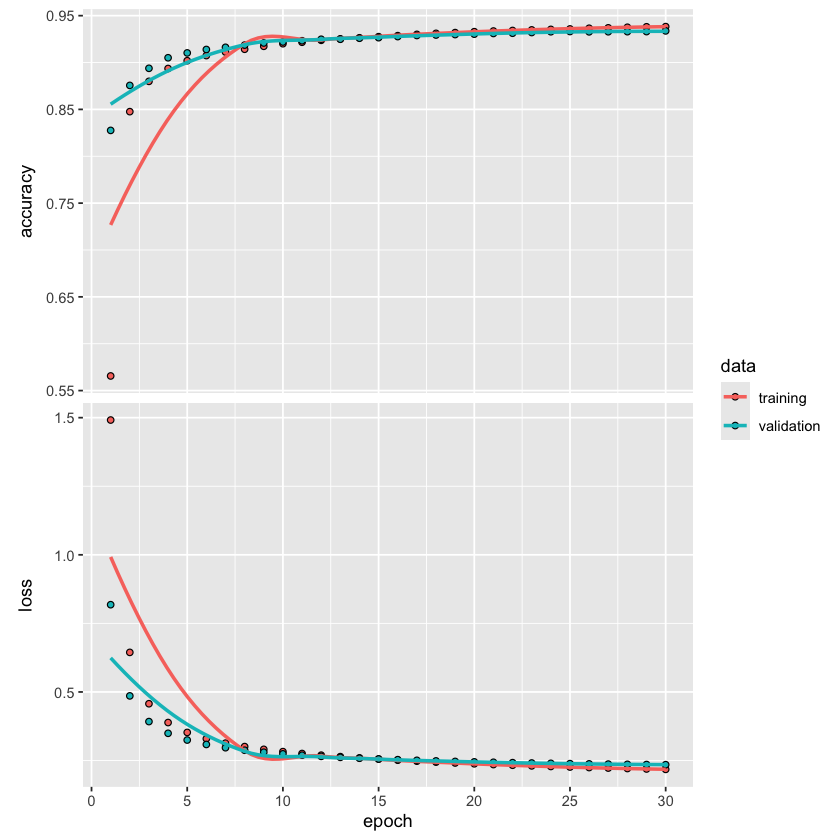

In [20]:
plot(history)

In [21]:
eval1 <- model %>% evaluate(x_test, y_test)
eval1

$accuracy
[1] 0.9333

$loss
[1] 0.228348

In [22]:
probs <- model %>% predict(x_test)   # matriz 10.000 x 10 de probabilidades
y_hat <- max.col(probs) - 1           # categoría con probabilidad más alta (0-9)
head(y_hat)

[1] 7 2 1 0 4 1

In [23]:
confusionMatrix(data = factor(as.numeric(y_hat), levels = 0:9), 
  reference = factor(mnist$test$y, levels = 0:9))

Confusion Matrix and Statistics

          Reference
Prediction    0    1    2    3    4    5    6    7    8    9
         0  955    0   10    1    2    6   10    2    6   11
         1    0 1109    4    0    2    1    3   13    7    9
         2    1    4  960   29   10    5    7   20    2    2
         3    1    1    9  918    0   34    1    8   22    9
         4    2    1    6    2  928    9    7    9   11   33
         5    3    0    3   21    1  790   11    0   15    5
         6   13    3   10    2    8   13  917    0   10    0
         7    1    2    9    9    2    5    1  949   11   12
         8    4   15   20   22    6   24    1    1  886    7
         9    0    0    1    6   23    5    0   26    4  921

Overall Statistics
                                          
               Accuracy : 0.9333          
                 95% CI : (0.9282, 0.9381)
    No Information Rate : 0.1135          
    P-Value [Acc > NIR] : < 2.2e-16       
                                         

## Teorema de Aproximación Universal y Redes Profundas


### ¿Por qué funcionan las redes neuronales?

Un aspecto clave del diseño de redes neuronales es determinar la **arquitectura**: cuántas unidades debe tener la red y cómo deben conectarse entre sí.

El **Teorema de Aproximación Universal** (Cybenko, 1989; Hornik, Stinchcombe & White, 1989; Leshno, Lin, Pinkus & Schocken, 1993) garantiza que una red suficientemente grande puede aproximar cualquier función continua. Formalmente, si la activación $g$ no es un polinomio, una red con una sola capa oculta y suficientes unidades puede aproximar cualquier función continua $f^*$ definida sobre un conjunto compacto (cerrado y acotado) de $\mathbb{R}^p$, con precisión arbitraria en todos los puntos a la vez:

$$f(X) = \beta_0 + \sum_{k=1}^{K} \beta_k \, g\!\left(w_{k0} + \sum_{j=1}^{p} w_{kj} X_j\right)$$


En principio, una sola capa oculta es suficiente. Entonces, ¿para qué agregar más capas?


## Arquitectura de redes y capas múltiples

<div >
    <img src = "figs/red_neuronal_2.png" />
</div>

In [24]:
set_random_seed(20261028)
model2 <- keras_model_sequential()

model2 %>%
layer_dense(units = 256, activation = 'relu', input_shape = c(784)) %>% 
layer_dense(units = 128, activation = 'relu') %>%
layer_dense(units = 10, activation = 'softmax')

In [25]:
summary(model2)

Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                   │ (None, 256)              │       200,960 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_3 (Dense)                   │ (None, 128)              │        32,896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_4 (Dense)                   │ (None, 10)               │         1,290 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘
 Total params: 235,146 (918.54 KB)
 Trainable params: 235,146 (918.54 KB)
 Non-trainable params: 0 (0.00 B)


In [26]:
model2 %>% compile(
  optimizer = 'adam',
  loss = 'categorical_crossentropy',
  metrics = c('accuracy')
)

In [27]:
history2 <- model2 %>% fit(
  x_train, y_train, 
  epochs = 8, 
  batch_size = 128,
  validation_split = 0.2
)

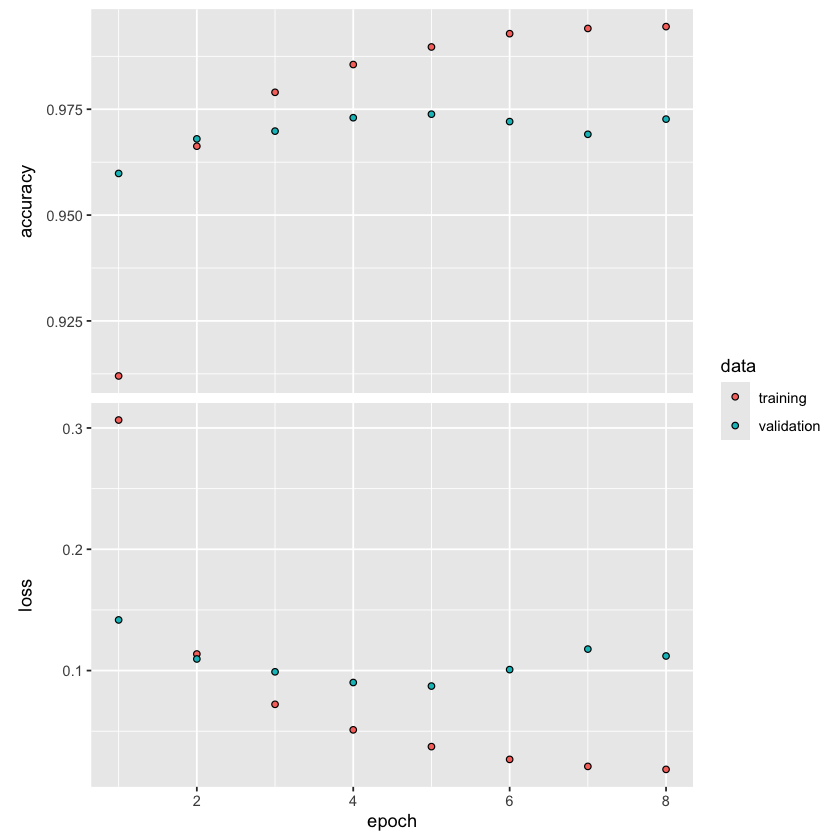

In [28]:
plot(history2)

In [29]:
eval2 <- model2 %>% evaluate(x_test, y_test)
eval2

$accuracy
[1] 0.9744

$loss
[1] 0.1045096

## Regularización en Redes Neuronales



### L1, L2 y Elastic Net 


$$L_{\text{reg}}(\theta) = L(\theta) + \lambda \|W\|_2^2 \quad (\text{L2 / Ridge})$$

$$L_{\text{reg}}(\theta) = L(\theta) + \lambda \|W\|_1 \quad (\text{L1 / Lasso})$$

$$L_{\text{reg}}(\theta) = L(\theta) + \lambda_1 \|W\|_1 + \lambda_2 \|W\|_2^2 \quad (\text{Elastic Net})$$


En `keras` se aplican así dentro de cada `layer_dense`:

```
# L2
kernel_regularizer = regularizer_l2(0.001)

# L1
kernel_regularizer = regularizer_l1(0.001)

# Elastic Net
kernel_regularizer = regularizer_l1_l2(l1 = 0.001, l2 = 0.001)
```

### Regularización implícita: early stopping y dropout



#### Early Stopping

La pregunta práctica más frecuente en redes neuronales es: **¿cuántas épocas entreno?**

- Pocas épocas → underfitting: el modelo no aprendió suficiente.
- Muchas épocas → overfitting: el modelo memorizó el training set.

**Early stopping** resuelve esto automáticamente: monitorea la pérdida en validación y **detiene el entrenamiento cuando deja de mejorar**, sin necesidad de fijar el número de épocas de antemano.

Los parámetros clave son:

- **`monitor`**: qué métrica observar (generalmente `la pérdida en validación`).
- **`patience`**: cuántas épocas sin mejora tolerar antes de parar. Un valor de 5–10 es razonable; muy bajo se detiene prematuramente, muy alto pierde el punto.
- **`restore_best_weights = TRUE`**: al terminar, restaura los pesos del mejor epoch (no del último). Esto es crucial (sin esto, el modelo final sería el del epoch donde ya empezó a sobreajustar).



Entrenamiento detenido en época: 15 de 100 
Mejor época (pesos restaurados): 5 


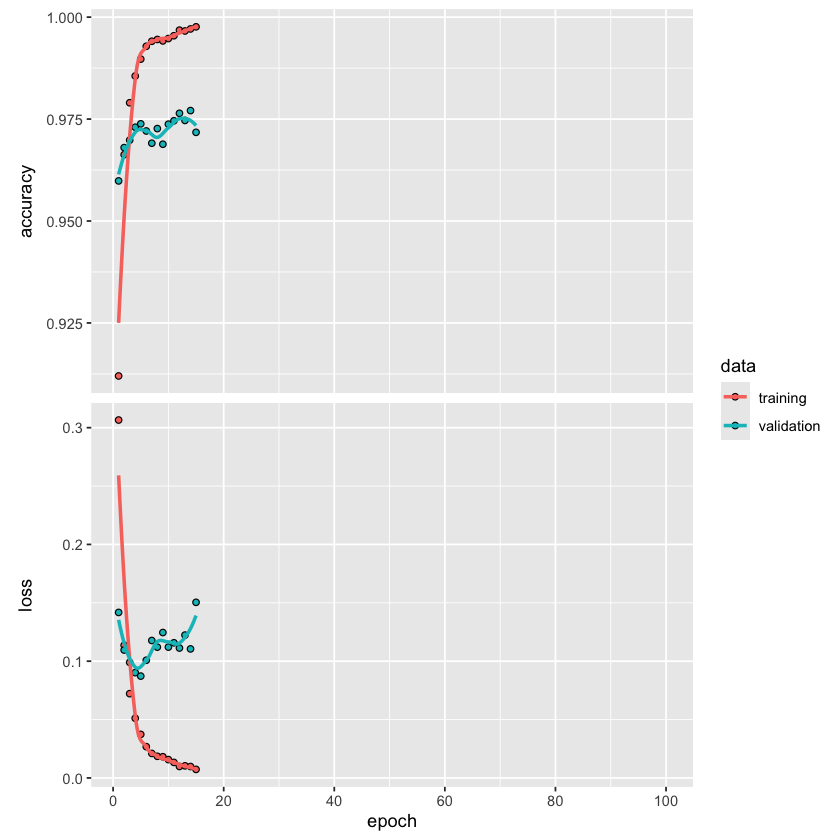

In [30]:
# Early stopping

set_random_seed(20261028) 

model2_es <- keras_model_sequential() %>%
  layer_dense(units = 256, activation = 'relu', input_shape = c(784)) %>%
  layer_dense(units = 128, activation = 'relu') %>%
  layer_dense(units = 10, activation = 'softmax')

model2_es %>% compile(
  optimizer = 'adam',
  loss = 'categorical_crossentropy',
  metrics = c('accuracy')
)

early_stop <- callback_early_stopping(
  monitor              = "val_loss",  # observamos la pérdida en validación
  patience             = 10,          # toleramos 10 épocas sin mejora
  restore_best_weights = TRUE         # volvemos al mejor modelo al terminar
)

history2_es <- model2_es %>% fit(
  x_train, y_train,
  epochs           = 100,        # máximo posible —> early stopping decide
  batch_size       = 128,
  validation_split = 0.2,
  callbacks        = list(early_stop),
  verbose          = 1
)

cat("\nEntrenamiento detenido en época:", length(history2_es$metrics$val_loss), "de 100",
    "\nMejor época (pesos restaurados):", which.min(history2_es$metrics$val_loss), "\n")
plot(history2_es)

In [31]:
eval2_es <- model2_es %>% evaluate(x_test, y_test)
eval2_es

$accuracy
[1] 0.9771

$loss
[1] 0.07832462


#### Dropout Learning

En cada paso de entrenamiento, cada unidad de una capa con dropout se **apaga** con probabilidad $\phi$ (la tasa de dropout, `rate`). Para cada unidad se sortea una máscara $m_k \sim \text{Bernoulli}(1-\phi)$, distinta para cada observación del mini-batch y nueva en cada paso. Las unidades que sobreviven se multiplican por $1/(1-\phi)$:

$$
\tilde h_k = \frac{m_k}{1-\phi}\, h_k, \qquad \mathbb{E}[\tilde h_k] = h_k,
$$

así que en promedio cada unidad entrega lo mismo que sin dropout. Cada paso entrena una subred distinta. Ninguna unidad puede depender de que otra específica esté prendida, lo que evita que las unidades se "co-adapten" y sobreajusten.

**Al predecir no se apaga nada**: `predict()` y `evaluate()` usan todas las unidades, sin reescalar. La red completa funciona como un promedio de las $2^K$ subredes que comparten pesos: la misma idea de bagging y random forests, que aleatorizan para promediar modelos distintos.



In [32]:
set_random_seed(20261028)  

model3 <- keras_model_sequential() 

model3 %>%
layer_dense(units = 256, activation = 'relu', input_shape = c(784)) %>% 
layer_dropout(rate = 0.4) %>%
layer_dense(units = 128, activation = 'relu') %>%
layer_dropout(rate = 0.3) %>%
layer_dense(units = 10, activation = 'softmax')

In [33]:
model3 %>% compile(
  optimizer = 'adam',
  loss = 'categorical_crossentropy',
  metrics = c('accuracy')
)

In [34]:
summary(model3)

Model: "sequential_3"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                   │ (None, 256)              │       200,960 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 256)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_9 (Dense)                   │ (None, 128)              │        32,896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_1 (Dropout)               │ (None, 128)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_10 (Dense)                  │ (None, 10)               │         1,290 │
└─────

In [35]:
history3 <- model3 %>% fit(
  x_train, y_train, 
  epochs = 30, 
  batch_size = 128,
  validation_split = 0.2
)

In [36]:
eval3 <- model3 %>% evaluate(x_test, y_test)
eval3

$accuracy
[1] 0.9829

$loss
[1] 0.07467285

#### Batch normalization

Dentro de cada mini-batch $B$, la entrada de cada unidad se estandariza y después se reescala con dos parámetros que se aprenden, $\gamma$ y $\delta$:

$$
\hat z = \frac{z - \mu_B}{\sqrt{\sigma_B^2 + \varepsilon}}, \qquad \tilde z = \gamma\, \hat z + \delta
$$

Su objetivo principal es estabilizar y acelerar el entrenamiento; regulariza un poco como efecto secundario, porque $\mu_B$ y $\sigma_B$ cambian de un mini-batch a otro.


In [ ]:
set_random_seed(20261028)  

model4 <- keras_model_sequential() %>%
  layer_dense(units = 256, input_shape = c(784)) %>%
  layer_batch_normalization() %>%
  layer_activation('relu') %>%
  layer_dense(units = 128) %>%
  layer_batch_normalization() %>%
  layer_activation('relu') %>%
  layer_dense(units = 10, activation = 'softmax')

model4 %>% compile(
  optimizer = 'adam',
  loss = 'categorical_crossentropy',
  metrics = c('accuracy')
)

summary(model4)

Model: "sequential_4"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape           ┃     Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ dense_11 (Dense)              │ (None, 256)            │     200,960 │   Y   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ batch_normalization           │ (None, 256)            │       1,024 │   Y   │
│ (BatchNormalization)          │                        │             │       │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ activation (Activation)       │ (None, 256)            │           0 │   -   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ dense_12 (Dense)              │ (None, 128)            │      32,896 │   Y   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ batc

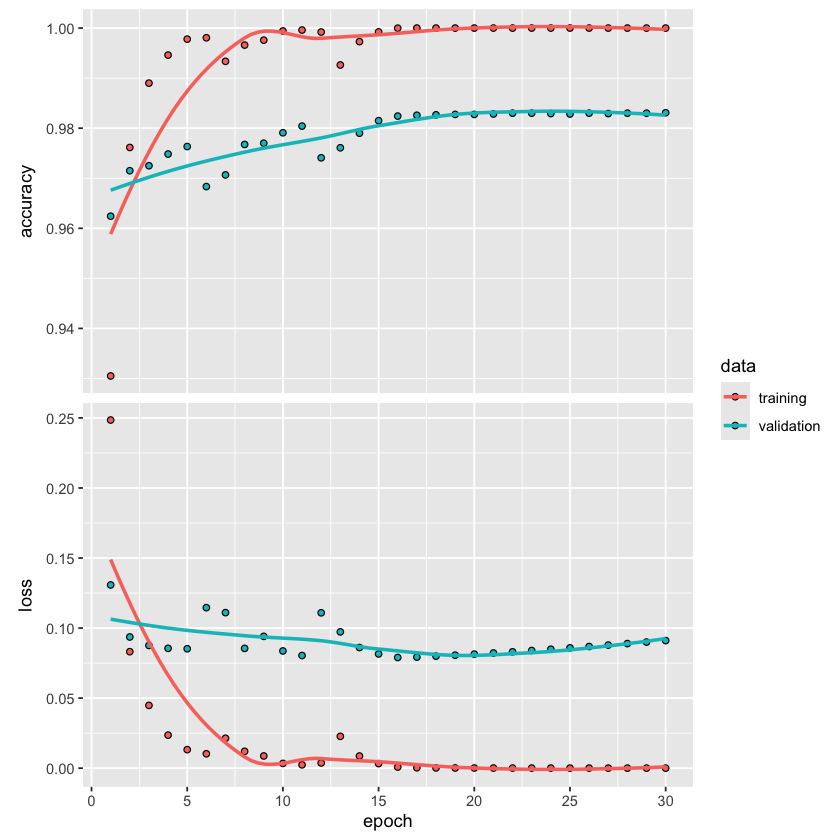

In [38]:
history4 <- model4 %>% fit(
  x_train, y_train,
  epochs = 30,
  batch_size = 128,
  validation_split = 0.2
)
plot(history4)

In [39]:
eval4 <- model4 %>% evaluate(x_test, y_test)
eval4

$accuracy
[1] 0.9832

$loss
[1] 0.08180653